# 00 — Point Robot and Expert Demonstrations

We start with the simplest possible continuous-control problem.

A point robot moves in a 2D workspace from a start position to a goal while
avoiding an obstacle.

The environment is deliberately simple: the objective is not to study physics,
but to isolate the learning problem that will later appear in robotic
manipulation.

We will use this environment to introduce:

- state, observation, and action
- dynamics
- policy
- trajectory and episode
- expert demonstrations
- multimodal behavior

## State, observation, and action

At time $t$, the robot position is

$$
p_t = [x_t, y_t].
$$

The complete environment state also contains the goal and obstacle:

$$
s_t = (p_t, p_g, \mathcal O).
$$

A policy does not necessarily observe the complete state. We denote its
observation by

$$
o_t.
$$

For our first experiments, the observation will contain the robot and goal
positions:

$$
o_t = [x_t, y_t, x_g, y_g].
$$

The action is a desired 2D displacement:

$$
a_t = [\Delta x_t, \Delta y_t].
$$

In [11]:
import numpy as np
import matplotlib.pyplot as plt

START = np.array([0.0, 0.0])
GOAL = np.array([0.0, 1.0])

MAX_ACTION = 0.05

In [12]:
# Simulate a step in the environment
def step(position, action):
    norm = np.linalg.norm(action)

    if norm > MAX_ACTION:
        action = action / norm * MAX_ACTION

    return position + action

In [13]:
# Define an expert policy for the point robot, which moves directly towards the goal (scripted policy)
def expert_policy(position, goal):
    direction = goal - position
    distance = np.linalg.norm(direction)

    if distance < 1e-8:
        return np.zeros(2)

    return direction / distance * min(distance, MAX_ACTION)

In [14]:
def make_observation(position, goal):
    return np.concatenate([position, goal])


def rollout(policy, start, goal, max_steps=100):
    position = start.copy()

    observations = []
    actions = []
    positions = [position.copy()]

    for _ in range(max_steps):
        observation = make_observation(position, goal)
        action = policy(position, goal)

        observations.append(observation)
        actions.append(action)

        position = step(position, action)
        positions.append(position.copy())

        if np.linalg.norm(position - goal) < 1e-3:
            break

    return {
        "observations": np.array(observations),
        "actions": np.array(actions),
        "positions": np.array(positions),
    }

observations: (20, 4)
actions:      (20, 2)
positions:    (21, 2)


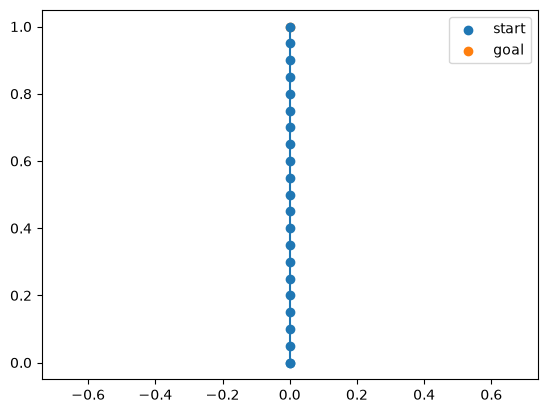

In [15]:
trajectory = rollout(expert_policy, START, GOAL)

print("observations:", trajectory["observations"].shape)
print("actions:     ", trajectory["actions"].shape)
print("positions:   ", trajectory["positions"].shape)

plt.plot(trajectory["positions"][:, 0], trajectory["positions"][:, 1], "-o")
plt.scatter(*START, label="start")
plt.scatter(*GOAL, label="goal")

plt.axis("equal")
plt.legend()
plt.show()

## Multimodal expert behavior

Going directly toward the goal is no longer possible if an obstacle blocks the
shortest path.

There are multiple valid solutions to the same task: for example, the robot can
go around the obstacle from the left or from the right.

We will construct a scripted expert capable of generating both behaviors.

In [24]:
# Rectangular obstacle in the environment for simplicity
OBSTACLE = {
    "xmin": -0.20,
    "xmax":  0.20,
    "ymin":  0.35,
    "ymax":  0.65,
}

Let's define a simple expert which can avoid obstacle moving for a predefined waypoint, either left or right 

In [25]:
LEFT_WAYPOINT = np.array([-0.35, 0.50])
RIGHT_WAYPOINT = np.array([0.35, 0.50])

In [26]:
def move_towards(position, target):
    direction = target - position
    distance = np.linalg.norm(direction)

    if distance < 1e-8:
        return np.zeros(2)

    return direction / distance * min(distance, MAX_ACTION)


def waypoint_expert(position, goal, waypoint):
    if position[1] < waypoint[1]:
        target = waypoint
    else:
        target = goal

    return move_towards(position, target)


def left_expert(position, goal):
    return waypoint_expert(position, goal, LEFT_WAYPOINT)


def right_expert(position, goal):
    return waypoint_expert(position, goal, RIGHT_WAYPOINT)


In [27]:
# Rollout the left and right expert policies to generate trajectories
left_trajectory = rollout(left_expert, START, GOAL)
right_trajectory = rollout(right_expert, START, GOAL)

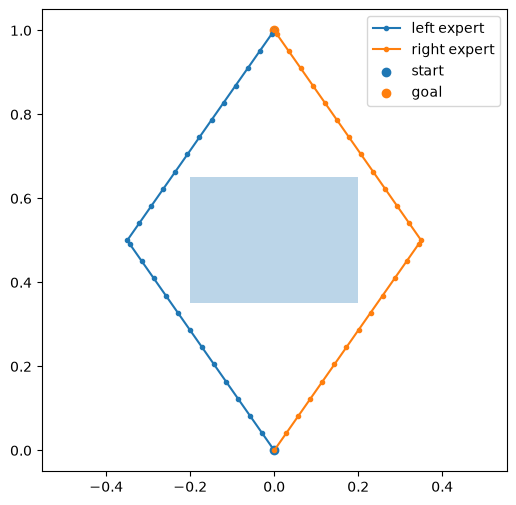

In [28]:
plt.figure(figsize=(6, 6))

plt.plot(
    left_trajectory["positions"][:, 0],
    left_trajectory["positions"][:, 1],
    "-o",
    markersize=3,
    label="left expert",
)

plt.plot(
    right_trajectory["positions"][:, 0],
    right_trajectory["positions"][:, 1],
    "-o",
    markersize=3,
    label="right expert",
)

plt.scatter(*START, label="start")
plt.scatter(*GOAL, label="goal")

rect = plt.Rectangle(
    (OBSTACLE["xmin"], OBSTACLE["ymin"]),
    OBSTACLE["xmax"] - OBSTACLE["xmin"],
    OBSTACLE["ymax"] - OBSTACLE["ymin"],
    alpha=0.3,
)

plt.gca().add_patch(rect)

plt.xlim(-0.6, 0.6)
plt.ylim(-0.1, 1.1)
plt.axis("equal")
plt.legend()
plt.show()

Multimodal: we have for a same observation $o_0$ two different expert actions, $a^R$ (move right) and $a^L$ (move left) to avoid center obstacle 

## Dataset

Lets randomize start and goal position to have different trajectories when rolling out policies

In [ ]:
# Fix seed for reproducibility
rng = np.random.default_rng(seed=42)

def sample_task(rng):
    start = np.array([
        rng.uniform(-0.1, 0.1),
        0.0,
    ])

    goal = np.array([
        rng.uniform(-0.1, 0.1),
        1.0,
    ])

    return start, goal

In [31]:
for _ in range(5):
    start, goal = sample_task(rng)
    print("start:", start, "goal:", goal)

start: [0.05479121 0.        ] goal: [-0.01222431  1.        ]
start: [0.07171958 0.        ] goal: [0.03947361 1.        ]
start: [-0.08116453  0.        ] goal: [0.09512447 1.        ]
start: [0.05222794 0.        ] goal: [0.05721286 1.        ]
start: [-0.07437727  0.        ] goal: [-0.00992281  1.        ]


In [32]:
def collect_demonstrations(n_episodes, seed=42):
    rng = np.random.default_rng(seed)

    demonstrations = []

    for _ in range(n_episodes):
        start, goal = sample_task(rng)

        if rng.random() < 0.5:
            expert = left_expert
            strategy = "left"
        else:
            expert = right_expert
            strategy = "right"

        trajectory = rollout(
            expert,
            start,
            goal,
        )

        trajectory["strategy"] = strategy
        demonstrations.append(trajectory)

    return demonstrations

Collect an imitation-learning dataset

In [33]:
demonstrations = collect_demonstrations(
    n_episodes=200,
    seed=42,
)

len(demonstrations)

200

Lets inspect one demonstration in the dataset:

In [35]:
demo = demonstrations[0]

print("strategy:", demo["strategy"])
print("observations:", demo["observations"].shape)
print("actions:", demo["actions"].shape)
print("positions:", demo["positions"].shape)

print("first observation:", demo["observations"][0])
print("first action:", demo["actions"][0])

strategy: right
observations: (25, 4)
actions: (25, 2)
positions: (26, 2)
first observation: [ 0.05479121  0.         -0.01222431  1.        ]
first action: [0.02542078 0.04305559]


Let's visualize a few demonstrations to see the different strategies in action. It can be recognized how trajectories are grouped in two main families of trajectories, which represent the **modes** of our expert distribution  

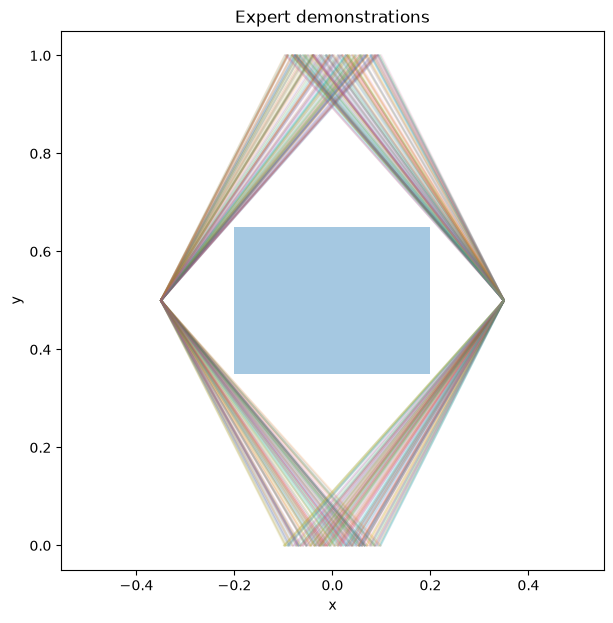

In [37]:
plt.figure(figsize=(7, 7))

for demo in demonstrations:
    positions = demo["positions"]

    plt.plot(
        positions[:, 0],
        positions[:, 1],
        alpha=0.15,
    )

rect = plt.Rectangle(
    (OBSTACLE["xmin"], OBSTACLE["ymin"]),
    OBSTACLE["xmax"] - OBSTACLE["xmin"],
    OBSTACLE["ymax"] - OBSTACLE["ymin"],
    alpha=0.4,
)

plt.gca().add_patch(rect)

plt.xlim(-0.6, 0.6)
plt.ylim(-0.1, 1.1)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Expert demonstrations")
plt.axis("equal")
plt.show()